# Forecast Experiment Agent

Can an LLM agent do the modelling loop of a forecasting project: form a hypothesis, change the config, run a backtest, read the result and decide what to try next? This notebook compares an agent with random search and with my own hand-tuned config on the GEFCom2014 load-forecasting task. It only reads the run logs and re-runs nothing.

**Status:** random search is done. The agent runs and the once-only evaluation on unseen data are still to come, so the agent isn't in the figures yet.

## The setup

- **Task:** month-ahead probabilistic forecasts of electricity load, scored by pinball loss (lower is better) on 7 development months, October 2010 to April 2011.
- **Search:** every search starts from the plain model and gets 20 experiments over the same 11 settings: tree parameters, recency weighting, temperature scenarios and temperature features.
- **Accept rule, fixed in code:** a config becomes the new best only if its dev loss is more than 1% below the current best and it is better in at least 4 of the 7 months.
- **Scoring during the search:** a cheaper version of the backtest with 9 quantiles, checked beforehand to rank four test configs the same way as the full one. Its losses differ from the full backtest's, so the numbers here only compare with each other.
- **Unseen data:** the holdout and extended periods stay unopened until every search has finished. Each search's best config is then scored on them once.

## Architecture

Both searchers go through the same experiment core (`src/tools.py`). They differ only in how the next proposal is chosen.

```
 searcher             LLM agent (tool use)  |  random search (seeded sampler)
    |  proposal: changes, hypothesis, expected_change_pct
    v
 guardrails           leakage or invalid     -> rejected, logged, no budget used
    v
 duplicate check      config already run     -> rejected, logged, no budget used
    v
 evaluation           GEFCom, fast tier, 7 dev months   (uses budget; a failed run is logged too)
    v
 accept rule          >1% lower dev loss and better in >= 4 of 7 months
    v
 run log              runs/<run_id>/log.jsonl   (the result goes back to the searcher)


 final evaluation     scripts/final_eval.py, run once after all searches have finished:
                      the accept rule's best config on the holdout / extended months.
                      No searcher can reach it.
```

- **The LLM proposes, code decides.** The guardrails, the duplicate check, the accept rule and the budget are code. The agent's own claim of its best config is logged, but the accept rule's best is what gets evaluated.
- **The final evaluation is out of reach.** The search space can't express folds or quantiles, the adapter always asks GEFCom for the development folds, and `tools.py` only calls the fast tier.

In [1]:
from __future__ import annotations

import json
import re
import sys
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display
from matplotlib.ticker import MultipleLocator

ROOT = Path.cwd().parent  # the notebook runs from notebooks/
sys.path.insert(0, str(ROOT))
from src.tasks.gefcom import build_config  # noqa: E402
from src.tools import MONTHS  # noqa: E402

SETTINGS = yaml.safe_load((ROOT / "configs" / "agent.yaml").read_text(encoding="utf-8"))
FULL_BUDGET = SETTINGS["budget"]["experiments"]  # test runs with a smaller budget stay out of the comparison


def load_runs() -> pd.DataFrame:
    """One row per experiment of every finished full-budget search. Compute time counts
    failed runs too, and cached results at what they originally took to compute."""
    rows: list[dict[str, Any]] = []
    for log in sorted((ROOT / "runs").glob("*/log.jsonl")):
        events = [json.loads(line) for line in log.read_text(encoding="utf-8").splitlines()]
        start, last = events[0], events[-1]
        if last["event"] != "finish" or start["budget"]["experiments"] != FULL_BUDGET:
            continue
        compute_min = sum(e["runtime_s"] for e in events if e["event"] in ("experiment", "error")) / 60
        rows += [{"searcher": start["searcher"], "seed": start["seed"], "run": log.parent.name,
                  "compute_min": compute_min, **e} for e in events if e["event"] == "experiment"]
    return pd.DataFrame(rows)


def hand_tuned_result() -> dict[str, Any]:
    """The hand-tuned config (GEFCom's dev.yaml) on the search tier, from the run cache."""
    base_path = ROOT / SETTINGS["gefcom_path"] / SETTINGS["base_config"]
    config = build_config(yaml.safe_load(base_path.read_text(encoding="utf-8")), {}, "fast")
    for path in (ROOT / "runs" / "cache").glob("fast_*.json"):
        entry = json.loads(path.read_text(encoding="utf-8"))
        if entry["config"] == config:
            return entry["result"]
    raise LookupError("the hand-tuned config has no fast-tier result in runs/cache")


runs = load_runs()
human = hand_tuned_result()
samples = runs[runs["id"] > 0]  # experiment 0 is the start config, outside the budget
NAMES = {"agent": "Agent", "random": "Random search"}

## Search curves

Random search gets close to my hand-tuned config but doesn't beat it. Each search accepted only one or two of its 20 samples.

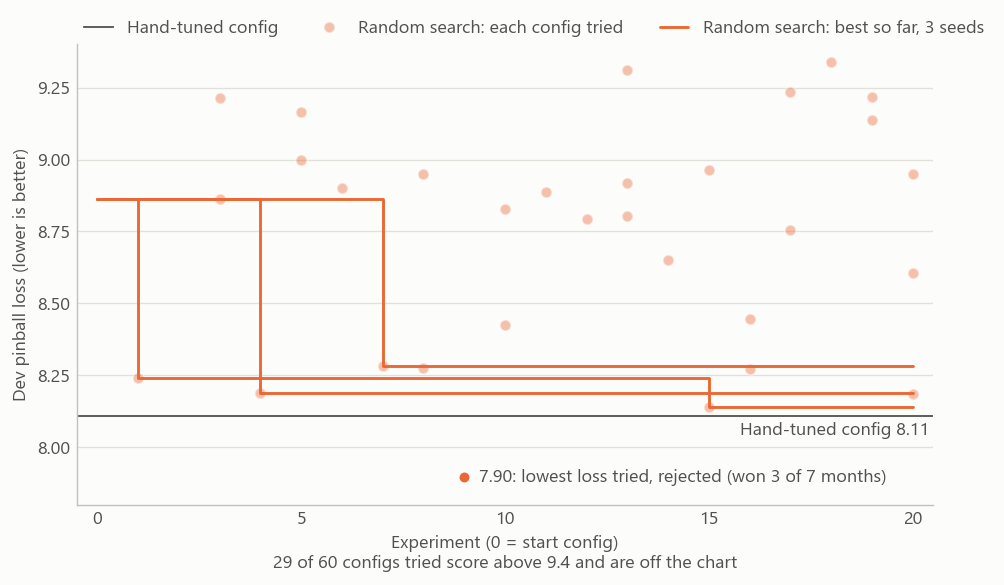

In [2]:
COLORS = {"agent": "#2a78d6", "random": "#eb6834"}  # fixed per searcher, so agent runs won't repaint random search
SURFACE, INK, GRID, AXIS = "#fcfcfb", "#52514e", "#e1e0d9", "#c3c2b7"
Y_RANGE = (7.8, 9.4)  # the best-so-far lines are the story; worse samples are only counted

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10})
fig, ax = plt.subplots(figsize=(8.5, 4.6), dpi=130, facecolor=SURFACE)
ax.set_facecolor(SURFACE)

ax.axhline(human["dev_loss"], color=INK, lw=1, label="Hand-tuned config")
ax.text(20.4, human["dev_loss"] - 0.02, f"Hand-tuned config {human['dev_loss']:.2f}", ha="right", va="top", color=INK)

for searcher, group in runs.groupby("searcher"):
    color, name = COLORS[searcher], NAMES[searcher]
    tried = group[group["id"] > 0]
    ax.plot(tried["id"], tried["dev_loss"], ls="none", marker="o", ms=6, mfc=color, mec=SURFACE, mew=1, alpha=0.4,
            label=f"{name}: each config tried")
    for i, (_, run) in enumerate(group.groupby("run")):
        ax.step(run["id"], run["best_dev_loss"], where="post", color=color, lw=1.6, solid_capstyle="round",
                solid_joinstyle="round", label=f"{name}: best so far, {group['seed'].nunique()} seeds" if i == 0 else None)

lowest = samples.loc[samples["dev_loss"].idxmin()]
if not lowest["accepted"]:
    won = re.search(r"won (\d+)/(\d+)", lowest["decision"]).groups()
    ax.plot(lowest["id"], lowest["dev_loss"], ls="none", marker="o", ms=7, mfc=COLORS[lowest["searcher"]], mec=SURFACE, mew=1.5)
    ax.annotate(f"{lowest['dev_loss']:.2f}: lowest loss tried, rejected (won {won[0]} of {won[1]} months)",
                (lowest["id"], lowest["dev_loss"]), xytext=(8, 0), textcoords="offset points", va="center", color=INK)

off_chart = int((samples["dev_loss"] > Y_RANGE[1]).sum())
ax.set_xlabel(f"Experiment (0 = start config)\n{off_chart} of {len(samples)} configs tried score above {Y_RANGE[1]} and are off the chart",
              color=INK)
ax.set_ylabel("Dev pinball loss (lower is better)", color=INK)
ax.set_xlim(-0.5, 20.5)
ax.set_ylim(*Y_RANGE)
ax.set_xticks(range(0, 21, 5))
ax.yaxis.set_major_locator(MultipleLocator(0.25))
ax.yaxis.set_major_formatter("{x:.2f}")
ax.tick_params(colors=INK, length=0)
ax.grid(axis="y", color=GRID, lw=0.75)
ax.set_axisbelow(True)
for side, spine in ax.spines.items():
    spine.set_visible(side in ("left", "bottom"))
    spine.set_color(AXIS)
ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=INK, handlelength=1.6, borderaxespad=0)
plt.show()

## Results on the development months

In [3]:
def pct(value: float, reference: float) -> str:
    return f"{100 * (value / reference - 1):+.1f}%"


start_loss = runs.loc[runs["id"] == 0, "dev_loss"].iloc[0]
rows = [{"Search": "Start config (plain model)", "Dev loss": f"{start_loss:.3f}"},
        {"Search": "Hand-tuned config", "Dev loss": f"{human['dev_loss']:.3f}", "vs. start": pct(human["dev_loss"], start_loss)}]
for (searcher, seed), group in runs.groupby(["searcher", "seed"]):
    best, lowest_tried = group[group["accepted"]].iloc[-1], group.loc[group["dev_loss"].idxmin()]
    rows.append({"Search": f"{NAMES[searcher]}, seed {seed}", "Best experiment": str(best["id"]),
                 "Dev loss": f"{best['dev_loss']:.3f}", "vs. start": pct(best["dev_loss"], start_loss),
                 "vs. hand-tuned": pct(best["dev_loss"], human["dev_loss"]),
                 "Lowest loss tried": f"{lowest_tried['dev_loss']:.3f}", "Compute (min)": f"{best['compute_min']:.0f}"})
columns = ["Best experiment", "Dev loss", "vs. start", "vs. hand-tuned", "Lowest loss tried", "Compute (min)"]
display(pd.DataFrame(rows).set_index("Search")[columns].fillna(""))

,Best experiment,Dev loss,vs. start,vs. hand-tuned,Lowest loss tried,Compute (min)
Search,,,,,,
Start config (plain model),,8.863,,,,
Hand-tuned config,,8.109,-8.5%,,,
"Random search, seed 0",4,8.188,-7.6%,+1.0%,7.897,47
"Random search, seed 1",15,8.141,-8.1%,+0.4%,8.141,33
"Random search, seed 2",7,8.283,-6.5%,+2.1%,8.271,41


## What the accept rule did

The rule rejected the lowest-loss config of all 60 samples (seed 0, experiment 9). Its loss is 3.6% below the best at that point, but it won only 3 of the 7 months: the gain comes from December and January, it lost February, and a near tie in October decided it.

Stopping a gain carried by two winter months is what the month rule is for, although a near tie counts as a full month. The rule stays as it was fixed before these results: changing it now would tune it on them, and the agent and random search face the same rule.

Below: every sample more than 1% better than the best at that point that the rule still rejected, month by month.

In [4]:
runs["best_before"] = runs.groupby("run")["best_dev_loss"].shift()
threshold = 1 - SETTINGS["accept_rule"]["min_rel_improvement"]
for _, row in runs[~runs["accepted"] & (runs["dev_loss"] < runs["best_before"] * threshold)].iterrows():
    best = runs[(runs["run"] == row["run"]) & (runs["id"] == row["best_id"])].iloc[0]
    months = pd.DataFrame({f"Best at that point (experiment {best['id']})": best["fold_losses"],
                           f"Rejected (experiment {row['id']})": row["fold_losses"]})
    months["Difference"] = months.iloc[:, 1] - months.iloc[:, 0]
    print(f"{NAMES[row['searcher']]}, seed {row['seed']}: {row['decision']}")
    display(months.rename(index=lambda fold: MONTHS[int(fold)]).round(3))

Random search, seed 0: rejected: dev loss 7.897 vs best 8.188 (3.6% lower; needs > 1.0% lower); won 3/7 months (needs >= 4)


,Best at that point (experiment 4),Rejected (experiment 9),Difference
Oct 2010,3.057,3.060,0.003
Nov 2010,5.173,5.449,0.276
Dec 2010,19.139,17.425,-1.714
Jan 2011,11.125,9.008,-2.117
Feb 2011,7.955,9.386,1.431
Mar 2011,7.003,7.401,0.398
Apr 2011,3.863,3.548,-0.315


## One agent trace

Every experiment of one agent search, with the hypothesis in the agent's own words. "Expected" is its prediction of the dev loss change against the best config at that point, "Actual" is what the run showed against the same reference. Below it, the proposals the guardrails rejected.

In [ ]:
from collections import Counter  # noqa: E402

from scripts.final_eval import log_row  # noqa: E402
from src.logging_utils import read_log  # noqa: E402

TRACE_RUN: str | None = None  # a run id from runs/, e.g. "agent_s0_<timestamp>"; None = the first agent search


def trace_tables(run: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Experiments and failed runs of one search in log order, and the proposals the guardrails rejected."""
    steps: list[dict[str, Any]] = []
    rejected: list[dict[str, Any]] = []
    best_loss = 0.0
    for e in read_log(ROOT / "runs" / run / "log.jsonl"):
        changes = ", ".join(f"{name}={value}" for name, value in e.get("changes", {}).items())
        if e["event"] == "experiment":
            expected = e["expected_change_pct"]
            actual = 100 * (e["dev_loss"] / best_loss - 1) if e["id"] else None  # experiment 0 has no reference
            steps.append({"#": e["id"], "Hypothesis": e["hypothesis"], "Changes": changes,
                          "Expected": "" if expected is None else f"{expected:+.1f}%",
                          "Actual": "" if actual is None else f"{actual:+.1f}%",
                          "Result": "accepted" if e["accepted"] else "rejected"})
            best_loss = e["best_dev_loss"]
        elif e["event"] == "error":
            steps.append({"#": e["id"], "Hypothesis": e["hypothesis"], "Changes": changes, "Expected": "",
                          "Actual": "", "Result": "failed run"})
        elif e["event"] == "rejected":
            rejected.append({"After experiment": steps[-1]["#"] if steps else 0, "Category": e["category"],
                             "Reason": e["reason"], "Hypothesis": e["hypothesis"], "Changes": changes})
    return pd.DataFrame(steps).set_index("#"), pd.DataFrame(rejected)


agent_runs = sorted(runs.loc[runs["searcher"] == "agent", "run"].unique())
trace_run = TRACE_RUN or (agent_runs[0] if agent_runs else None)
if trace_run is None:
    print("No finished agent search in runs/ yet.")
else:
    steps, rejected = trace_tables(trace_run)
    print(trace_run)
    with pd.option_context("display.max_colwidth", None):
        display(steps)
        print(f"\nRejected proposals, which used no budget: {len(rejected)}")
        if len(rejected):
            display(rejected.set_index("After experiment"))

## Self-correction

Prediction error per experiment: how far the agent's expected change was from the actual one, in percentage points of dev loss, both against the best config at that point. If the agent learns from its results, the errors should shrink over the search.

In [ ]:
before = runs.groupby("run")["best_dev_loss"].shift()
agent = runs[(runs["searcher"] == "agent") & (runs["id"] > 0)].assign(
    error=lambda d: (100 * (d["dev_loss"] / before[d.index] - 1) - d["expected_change_pct"]).abs()).dropna(subset=["error"])

if agent.empty:
    print("No finished agent search in runs/ yet.")
else:
    fig, ax = plt.subplots(figsize=(8.5, 3.6), dpi=130, facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    for (seed, group), style in zip(agent.groupby("seed"), ["-", "--", ":", "-."]):
        ax.plot(group["id"], group["error"], ls=style, marker="o", ms=5, lw=1.4, color=COLORS["agent"], mec=SURFACE,
                label=f"Agent, seed {seed}")
    ax.set_xlabel("Experiment", color=INK)
    ax.set_ylabel("|actual - expected| (percentage points)", color=INK)
    ax.set_xlim(0.5, 20.5)
    ax.set_xticks(range(1, 21, 2))
    ax.set_ylim(bottom=0)
    ax.tick_params(colors=INK, length=0)
    ax.grid(axis="y", color=GRID, lw=0.75)
    ax.set_axisbelow(True)
    for side, spine in ax.spines.items():
        spine.set_visible(side in ("left", "bottom"))
        spine.set_color(AXIS)
    ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=INK, borderaxespad=0)
    plt.show()

## Development vs. holdout

Each search's best config, scored once on the holdout months (read from `results/summary.csv`, written by `scripts/final_eval.py`). The dev column is the fast tier the searches saw (9 quantiles); the holdout and extended columns use 99 quantiles. Raw losses of different columns must not be compared, so every cell is the change against the hand-tuned config within its own column (lower is better). The first row gives that reference loss.

In [ ]:
SUMMARY = ROOT / "results" / "summary.csv"
LOSS_COLUMNS = {"dev_loss": "Dev (fast tier)", "holdout_loss": "Holdout (99 quantiles)",
                "extended_loss": "Extended (99 quantiles)"}

if not SUMMARY.exists():
    print("results/summary.csv doesn't exist yet: python -m scripts.final_eval --folds holdout --runs ...")
else:
    summary = pd.read_csv(SUMMARY)
    reference = summary[summary["searcher"] == "human"].iloc[0]
    table = [{"Search": "Hand-tuned config (loss)",
              **{name: f"{reference[col]:.3f}" for col, name in LOSS_COLUMNS.items() if pd.notna(reference[col])}}]
    for _, row in summary[summary["searcher"] != "human"].sort_values(["searcher", "seed"]).iterrows():
        table.append({"Search": f"{NAMES[row['searcher']]}, seed {int(row['seed'])}",
                      **{name: pct(row[col], reference[col]) for col, name in LOSS_COLUMNS.items()
                         if pd.notna(row[col]) and pd.notna(reference[col])}})
    display(pd.DataFrame(table).set_index("Search").fillna(""))

## Cost

What each search used, from its run log (the same numbers as in `results/summary.csv`). Wall time includes the LLM's latency and any cache hits from earlier searches. Compute time sums the GEFCom runtimes of the experiments and failed runs, with a cached result at what it originally took. Only the agent's API calls cost money.

In [ ]:
rows = []
for run in sorted(runs["run"].unique()):
    records = read_log(ROOT / "runs" / run / "log.jsonl")
    row, rejections = log_row(run, records), Counter(r["category"] for r in records if r["event"] == "rejected")
    rows.append({"Search": f"{NAMES[row['searcher']]}, seed {row['seed']}", "Cost (USD)": f"{row['cost_usd']:.2f}",
                 "Wall (min)": row["wall_minutes"], "Compute (min)": row["compute_minutes"],
                 "Leakage hits": row["leakage_hits"], "Invalid": rejections["invalid"],
                 "Duplicate": rejections["duplicate"], "Failed runs": sum(r["event"] == "error" for r in records),
                 "Stopped by": row["stop_reason"]})
display(pd.DataFrame(rows).set_index("Search"))

## Failure cases and limitations

- **Three seeds per searcher can't separate small differences.** A rerun of a config can't measure noise either: LightGBM is deterministic here, so a seed changes nothing. The three agent searches differ only by the model's sampling, because the API gives no seed or temperature to set.
- **The model may know GEFCom2014 from its training data.** The task description doesn't say which settings helped, and the space holds settings nobody tried and a known bad option, but that doesn't rule it out.
- **This is parameter search, not modelling code.** The agent picks among 11 settings of one model. Writing new features is a later step.
- **The accept rule has known trade-offs.** Each accepted best raises the bar on the same 7 months, so later accepts are partly selection on noise; the untouched holdout measures how much. A near tie counts as a full month. On its own the month rule is weak (a change with no effect wins at least 4 of 7 months half the time), so the 1% threshold does the noise filtering. The rule rejected random search's lowest-loss sample (above); it is fixed in advance and was not changed afterwards.
- **The search tier isn't the final tier.** The fast tier (9 quantiles, every second scenario shift day) was checked on four configs only, where it ranked them like the full backtest. A config that wins on the fast tier can still lose on 99 quantiles.
- **The guardrail count is a lower bound.** Only the oracle temperature and the evaluation folds count as leakage. Any other attempt outside the space is blocked too but counted as invalid.
- **Failed GEFCom runs use budget.** A run that times out (30 minutes) is logged as an error and can't be retried.
- **Extended folds are planned for only some configs** (the best agent, the best random search and the hand-tuned config), because a run takes hours.